# <center>**Chapter 25 - Building a Convolutional Neural Network in PyTorch**<center>

## **Mục tiêu**
- Hiểu vì sao convolution giữ cấu trúc không gian của ảnh và dùng ít tham số hơn kết nối đầy đủ.
- Ghép các lớp convolution, activation, pooling, dropout và fully connected để phân loại ảnh CIFAR-10.
- Trích xuất, quan sát feature maps từ hai lớp convolution.

CIFAR-10 gồm ảnh màu RGB kích thước `3 × 32 × 32` và 10 lớp. Phép convolution trượt các bộ lọc nhỏ trên ảnh; mỗi bộ lọc tạo một feature map. Pooling giảm kích thước không gian, còn các lớp fully connected tạo logits phân loại.

Notebook tuân theo kiến trúc và SGD trong PDF. Lần chạy đầu sẽ tải CIFAR-10 vào thư mục `data/cifar10`; huấn luyện 20 epoch trên CPU có thể mất nhiều thời gian.

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 32
N_EPOCHS = 20
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def find_lab_dir() -> Path:
    # Tìm thư mục Lab08a khi notebook được mở từ thư mục dự án hoặc thư mục bài lab.
    lab_name = "Lab08a - CNN Models"
    section_name = "Buổi thực hành số 8 (Convolutional Neural Network)"
    current = Path.cwd().resolve()
    for root in (current, *current.parents):
        for candidate in (
            root,
            root / lab_name,
            root / section_name / lab_name,
        ):
            if (candidate / "DL26 - CNN Models with PyTorch.pdf").is_file():
                return candidate
    raise FileNotFoundError("Không tìm thấy thư mục Lab08a - CNN Models.")

LAB_DIR = find_lab_dir()
DATA_DIR = LAB_DIR / "data" / "cifar10"

In [6]:
transform = transforms.ToTensor()

trainset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=True,
    download=True,
    transform=transform,
)
testset = datasets.CIFAR10(
    root=str(DATA_DIR),
    train=False,
    download=True,
    transform=transform,
)
trainloader = DataLoader(
    trainset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
testloader = DataLoader(
    testset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)

100%|██████████| 170M/170M [18:26<00:00, 154kB/s]    


In [7]:
print(f"Kích thước tập train/test: {len(trainset)}/{len(testset)}")
print(f"Kích thước một ảnh: {tuple(trainset[0][0].shape)}")
print(f"Thiết bị huấn luyện: {DEVICE}")
print("Tên lớp:", trainset.classes)

Kích thước tập train/test: 50000/10000
Kích thước một ảnh: (3, 32, 32)
Thiết bị huấn luyện: cpu
Tên lớp: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## **Kiến trúc CNN cho CIFAR-10**

Kiến trúc theo Listing 25.1 trong PDF:

`RGB 32×32 → Conv(3→32) → ReLU → Dropout → Conv(32→32) → ReLU → MaxPool(2) → Flatten(8192) → Linear(512) → ReLU → Dropout → Linear(10)`

Hai lớp convolution dùng kernel `3 × 3`, padding 1 để giữ kích thước ảnh cho tới pooling. Lớp cuối trả về **logits**; không thêm softmax vì `CrossEntropyLoss` đã xử lý phần này.

In [8]:
class CIFAR10Model(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)
        self.act1 = nn.ReLU()
        self.drop1 = nn.Dropout(p=0.3)
        self.conv2 = nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1)
        self.act2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.flat = nn.Flatten()
        self.fc3 = nn.Linear(32 * 16 * 16, 512)
        self.act3 = nn.ReLU()
        self.drop3 = nn.Dropout(p=0.5)
        self.fc4 = nn.Linear(512, 10)

    def forward(self, images: torch.Tensor) -> torch.Tensor:
        features = self.drop1(self.act1(self.conv1(images)))
        features = self.pool2(self.act2(self.conv2(features)))
        features = self.drop3(self.act3(self.fc3(self.flat(features))))
        return self.fc4(features)

In [9]:

model = CIFAR10Model().to(DEVICE)
sample_images, _ = next(iter(trainloader))
with torch.no_grad():
    sample_logits = model(sample_images.to(DEVICE))
print("Shape đầu vào:", tuple(sample_images.shape))
print("Shape logits:", tuple(sample_logits.shape))
print(f"Số tham số có thể học: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Shape đầu vào: (32, 3, 32, 32)
Shape logits: (32, 10)
Số tham số có thể học: 4,210,090


## **Huấn luyện và đánh giá**

Dùng SGD với learning rate `0.001`, momentum `0.9` và cross-entropy như trong PDF. Sau mỗi epoch, tính accuracy bằng `argmax` của logits và lưu `state_dict` sau khi huấn luyện.

Trong lần chạy hiện tại, mô hình được huấn luyện trên 50.000 ảnh và đánh giá trên 10.000 ảnh bằng CPU. Train loss giảm từ **2.0060** ở epoch 1 xuống **0.7148** ở epoch 20; test accuracy tăng từ **38.02%** lên **67.90%**. Mốc tham khảo trong PDF là trên 70%, nên kết quả lần chạy này chưa đạt mốc đó.

In [10]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)
history = {"train_loss": [], "test_accuracy": []}

for epoch in range(N_EPOCHS):
    model.train()
    total_loss = 0.0
    train_count = 0

    for images, labels in trainloader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        logits = model(images)
        loss = loss_fn(logits, labels)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        train_count += labels.size(0)

    model.eval()
    correct = 0
    test_count = 0
    with torch.inference_mode():
        for images, labels in testloader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()
            test_count += labels.size(0)

    epoch_loss = total_loss / train_count
    test_accuracy = correct / test_count
    history["train_loss"].append(epoch_loss)
    history["test_accuracy"].append(test_accuracy)
    print(
        f"Epoch {epoch + 1:02d}/{N_EPOCHS}: "
        f"train loss={epoch_loss:.4f}, "
        f"test accuracy={test_accuracy * 100:.2f}%"
    )

Epoch 01/20: train loss=2.0060, test accuracy=38.02%
Epoch 02/20: train loss=1.7125, test accuracy=44.29%
Epoch 03/20: train loss=1.5664, test accuracy=48.18%
Epoch 04/20: train loss=1.4690, test accuracy=51.32%
Epoch 05/20: train loss=1.3958, test accuracy=53.02%
Epoch 06/20: train loss=1.3412, test accuracy=55.25%
Epoch 07/20: train loss=1.2874, test accuracy=56.06%
Epoch 08/20: train loss=1.2353, test accuracy=57.98%
Epoch 09/20: train loss=1.1855, test accuracy=58.81%
Epoch 10/20: train loss=1.1341, test accuracy=60.97%
Epoch 11/20: train loss=1.0853, test accuracy=62.46%
Epoch 12/20: train loss=1.0431, test accuracy=62.92%
Epoch 13/20: train loss=0.9960, test accuracy=64.24%
Epoch 14/20: train loss=0.9506, test accuracy=63.90%
Epoch 15/20: train loss=0.9099, test accuracy=65.15%
Epoch 16/20: train loss=0.8691, test accuracy=66.59%
Epoch 17/20: train loss=0.8291, test accuracy=66.80%
Epoch 18/20: train loss=0.7866, test accuracy=67.06%
Epoch 19/20: train loss=0.7516, test accuracy=

In [11]:
model_path = LAB_DIR / "cifar10model.pth"
torch.save(model.state_dict(), model_path)
print(f"Đã lưu trọng số tại: {model_path}")

Đã lưu trọng số tại: D:\Programming\.vscode\Coding\Data Science\(!!!) 4.HK1 - Học sâu (Python)\Buổi thực hành số 8 (Convolutional Neural Network)\Lab08a - CNN Models\cifar10model.pth


## **Trực quan hóa feature maps**

Mỗi kênh đầu ra của convolution là một feature map. Lớp đầu thường phản hồi với đặc trưng cục bộ; lớp convolution kế tiếp kết hợp các kênh đó để tạo biểu diễn trừu tượng hơn. Ở đây dùng ảnh mẫu có cùng phép biến đổi như lúc huấn luyện và tắt dropout bằng `eval()`.

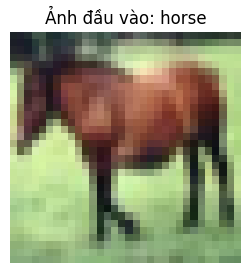

In [12]:
def show_feature_maps(feature_maps: torch.Tensor, title: str) -> None:
    maps = feature_maps[0].detach().cpu()
    figure, axes = plt.subplots(4, 8, figsize=(16, 8), sharex=True, sharey=True)
    figure.suptitle(title)
    for index, axis in enumerate(axes.flat):
        axis.imshow(maps[index], cmap="viridis")
        axis.set_xticks([])
        axis.set_yticks([])
    figure.tight_layout()
    plt.show()

model.load_state_dict(
    torch.load(model_path, map_location=DEVICE, weights_only=True)
)
model.eval()

sample_index = 7
image, label = trainset[sample_index]
input_batch = image.unsqueeze(0).to(DEVICE)

plt.figure(figsize=(3, 3))
plt.imshow(image.permute(1, 2, 0).cpu().numpy())
plt.title(f"Ảnh đầu vào: {trainset.classes[label]}")
plt.axis("off")
plt.show()

Kích thước feature maps lớp 1: (1, 32, 32, 32)
Kích thước feature maps lớp 2: (1, 32, 32, 32)


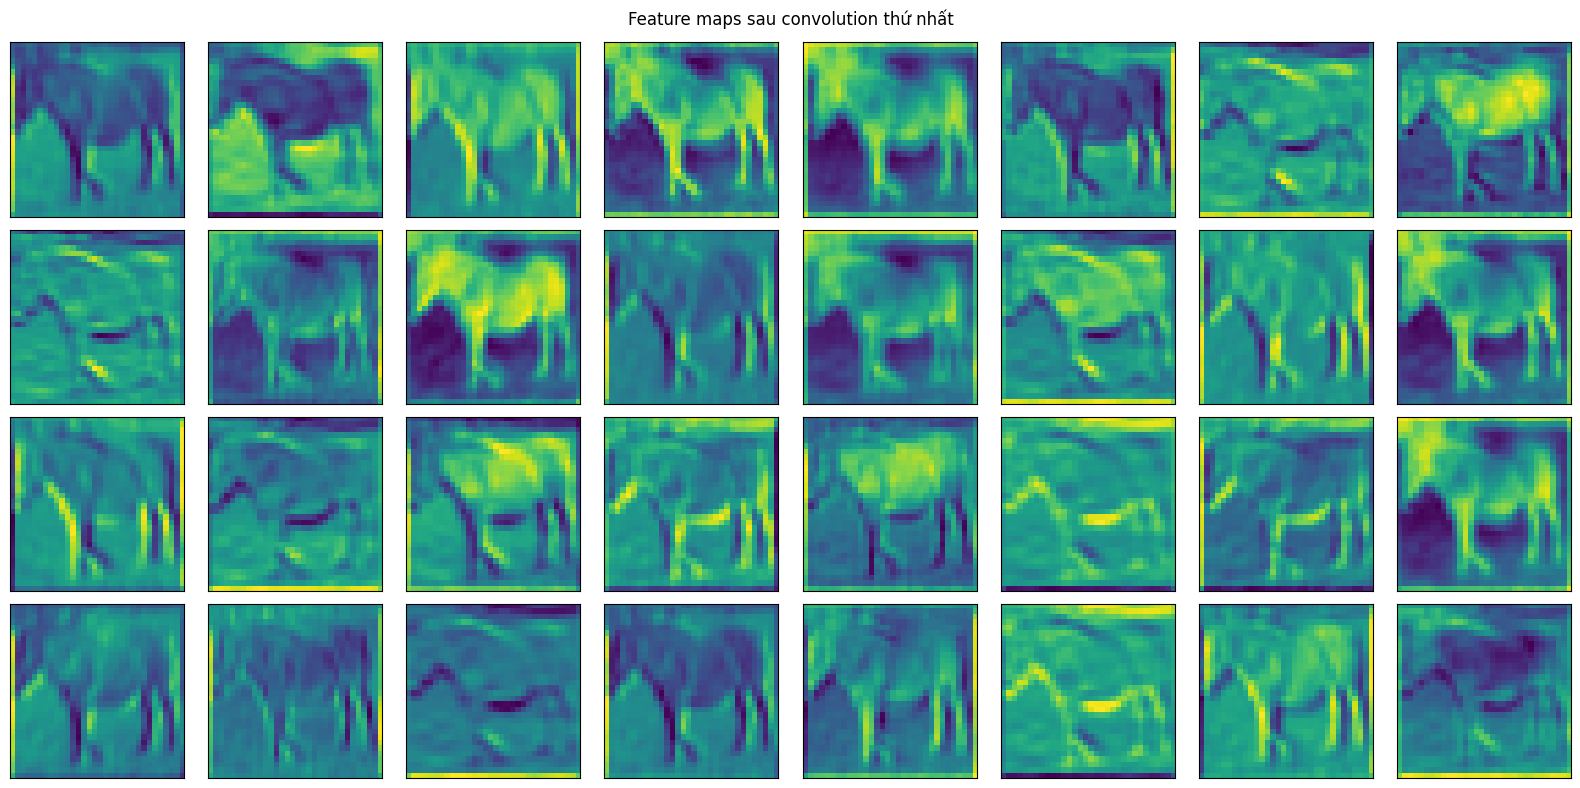

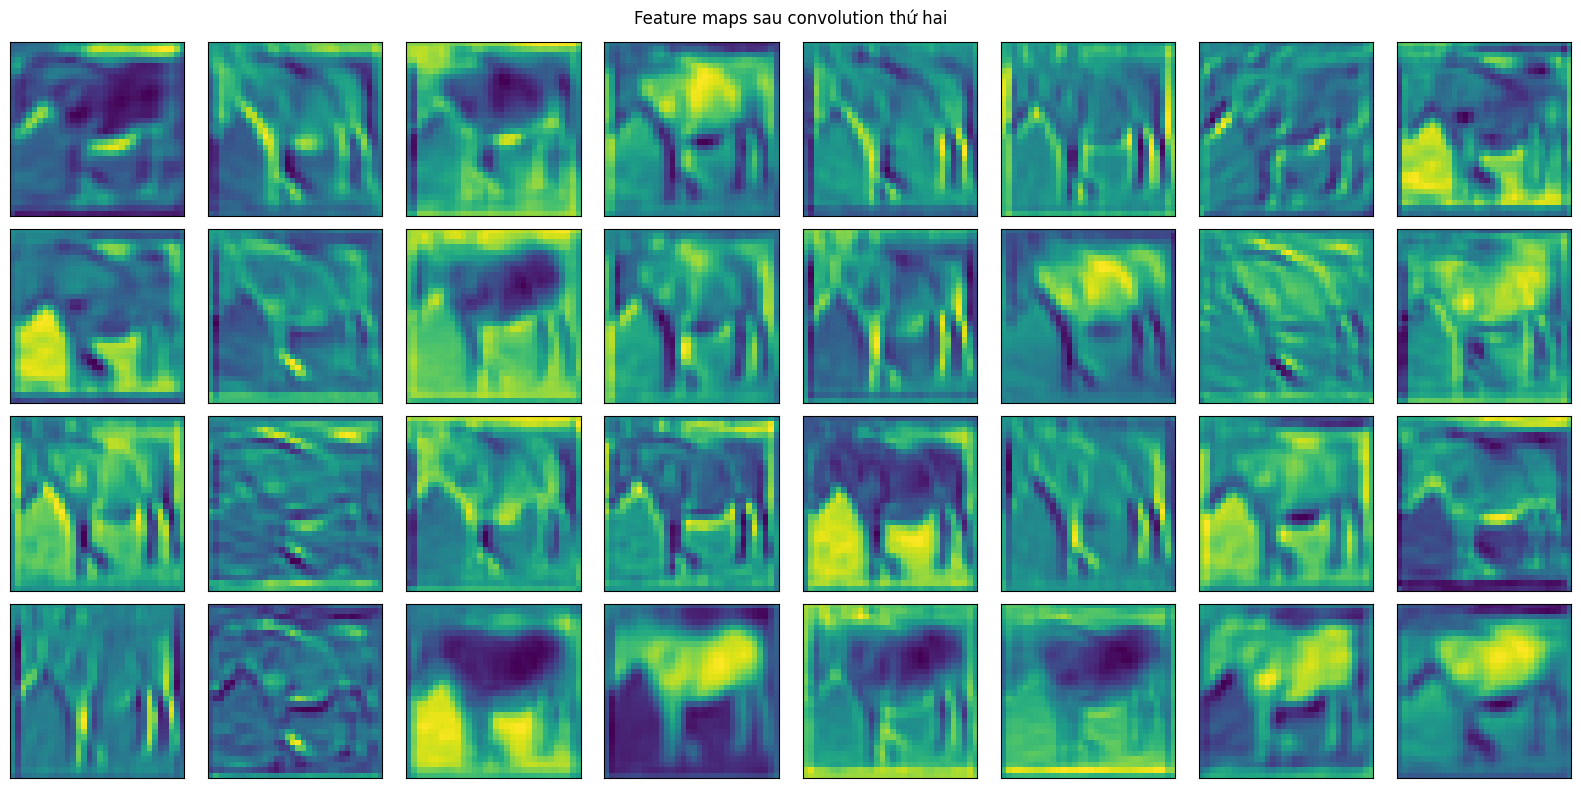

In [13]:
with torch.inference_mode():
    first_maps = model.conv1(input_batch)
    second_input = model.drop1(model.act1(first_maps))
    second_maps = model.conv2(second_input)

print("Kích thước feature maps lớp 1:", tuple(first_maps.shape))
print("Kích thước feature maps lớp 2:", tuple(second_maps.shape))
show_feature_maps(first_maps, "Feature maps sau convolution thứ nhất")
show_feature_maps(second_maps, "Feature maps sau convolution thứ hai")

## **Kết luận**

CNN kết hợp tính cục bộ và chia sẻ trọng số để giữ cấu trúc ảnh; pooling giảm kích thước bản đồ đặc trưng trước khi phân loại. Trong lần chạy này, đầu vào một batch có shape `(32, 3, 32, 32)`, đầu ra là 10 logits mỗi ảnh; hai lớp convolution tạo feature maps kích thước `(1, 32, 32, 32)` cho ảnh mẫu.

### **Kết quả và nhược điểm quan sát được**
- Sau 20 epoch, test accuracy đạt **67.90%**, thấp hơn mốc trên 70% được nêu trong PDF. Accuracy nhìn chung tăng nhưng có dao động giữa các epoch; cần thử thêm số epoch hoặc điều chỉnh siêu tham số để kiểm tra khả năng cải thiện.
- Mô hình có **4,210,090 tham số**; riêng lớp fully connected lớn, nên huấn luyện tốn thời gian và bộ nhớ hơn một mô hình CNN gọn hơn.
- Lần tải đầu lấy khoảng **170 MB** dữ liệu CIFAR-10 và mất khoảng **18 phút 26 giây** trong môi trường chạy này; những lần sau có thể dùng dữ liệu đã lưu trong cache.
- Theo đúng ví dụ trong PDF, test accuracy được theo dõi sau mỗi epoch. Khi phát triển mô hình thực tế, nên dùng validation để theo dõi/chọn cấu hình và chỉ đánh giá test ở cuối để tránh điều chỉnh mô hình dựa trên tập test.

Đây là kết quả của một lần chạy với seed và thiết bị cụ thể; accuracy có thể thay đổi khi đổi seed, phần cứng hoặc cấu hình huấn luyện.

# <center>**HẾT**<center>